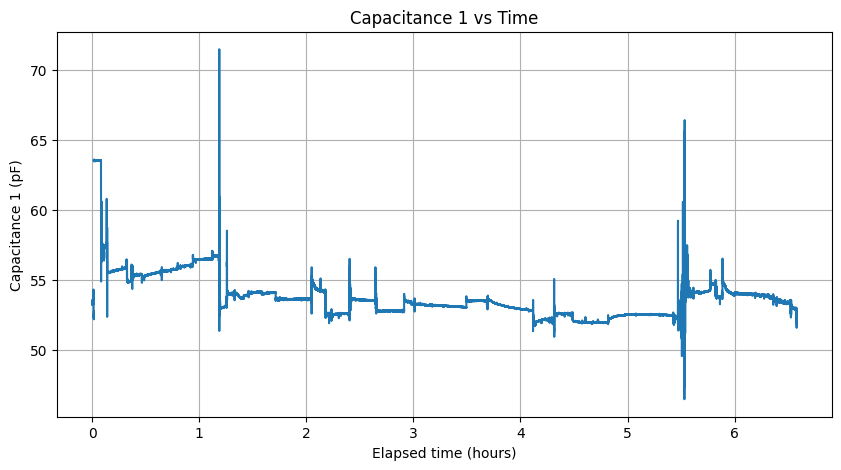

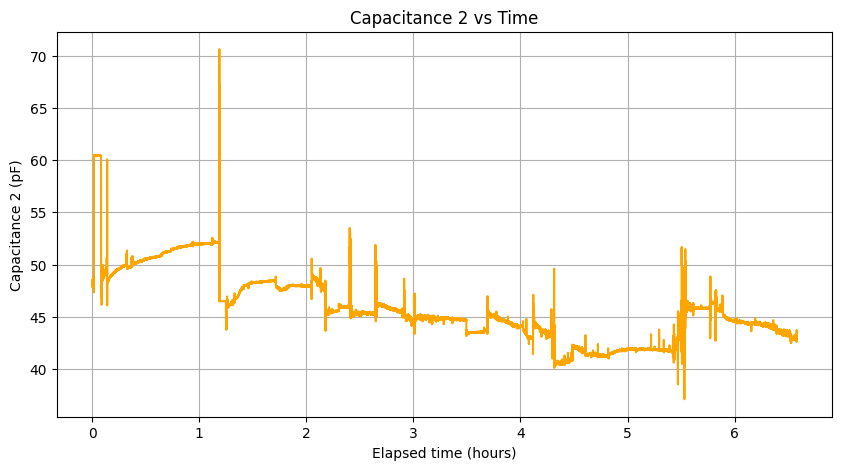

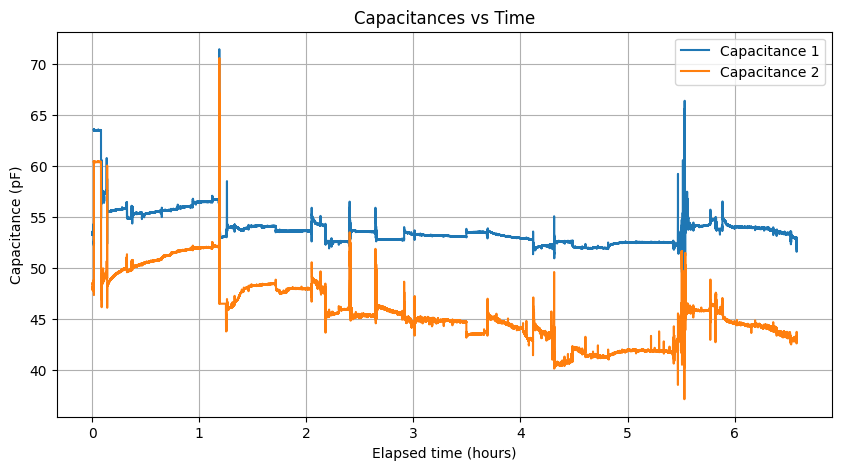

In [28]:
import pandas as pd

import matplotlib.pyplot as plt



file_path = "fdc1004_data_2026_10_15.csv"



data = pd.read_csv(file_path)

data.columns = data.columns.str.strip()



# Get column names from the CSV header row

timestamp_key, capacitance_1_key, capacitance_2_key = data.columns[:3]



time = data[timestamp_key]
time_hours = (time - time.iloc[0]) / 3600000

capacitance_1 = pd.to_numeric(data[capacitance_1_key], errors="coerce")

capacitance_2 = pd.to_numeric(data[capacitance_2_key], errors="coerce")



# Capacitance 1

plt.figure(figsize=(10, 5))

plt.plot(time_hours, capacitance_1)

plt.xlabel("Elapsed time (hours)")

plt.ylabel("Capacitance 1 (pF)")

plt.title("Capacitance 1 vs Time")

plt.grid(True)

plt.show()



# Capacitance 2

plt.figure(figsize=(10, 5))

plt.plot(time_hours, capacitance_2, color="orange")

plt.xlabel("Elapsed time (hours)")

plt.ylabel("Capacitance 2 (pF)")

plt.title("Capacitance 2 vs Time")

plt.grid(True)

plt.show()



# Both capacitances

plt.figure(figsize=(10, 5))

plt.plot(time_hours, capacitance_1, label="Capacitance 1")

plt.plot(time_hours, capacitance_2, label="Capacitance 2")

plt.xlabel("Elapsed time (hours)")

plt.ylabel("Capacitance (pF)")

plt.title("Capacitances vs Time")

plt.legend()

plt.grid(True)

plt.show()

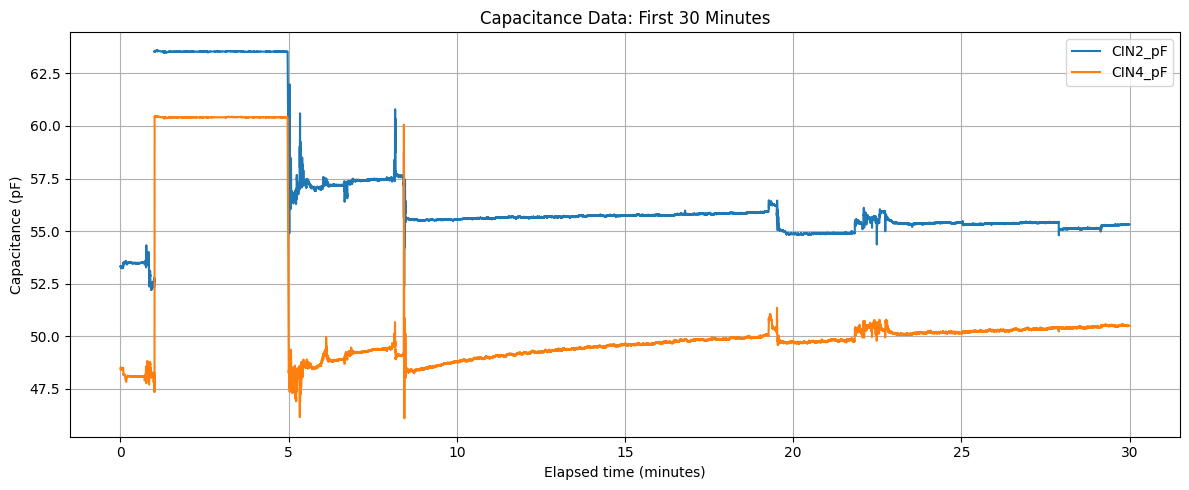

In [29]:
# Plot the first 30 minutes of both capacitance signals
start_time_ms = time.iloc[0]
end_time_ms = start_time_ms + 30 * 60 * 1000
mask_30_min = (time >= start_time_ms) & (time <= end_time_ms)

elapsed_minutes = (time[mask_30_min] - start_time_ms) / 60000

plt.figure(figsize=(12, 5))
plt.plot(elapsed_minutes, capacitance_1[mask_30_min], label=capacitance_1_key)
plt.plot(elapsed_minutes, capacitance_2[mask_30_min], label=capacitance_2_key)

plt.xlabel("Elapsed time (minutes)")
plt.ylabel("Capacitance (pF)")
plt.title("Capacitance Data: First 30 Minutes")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

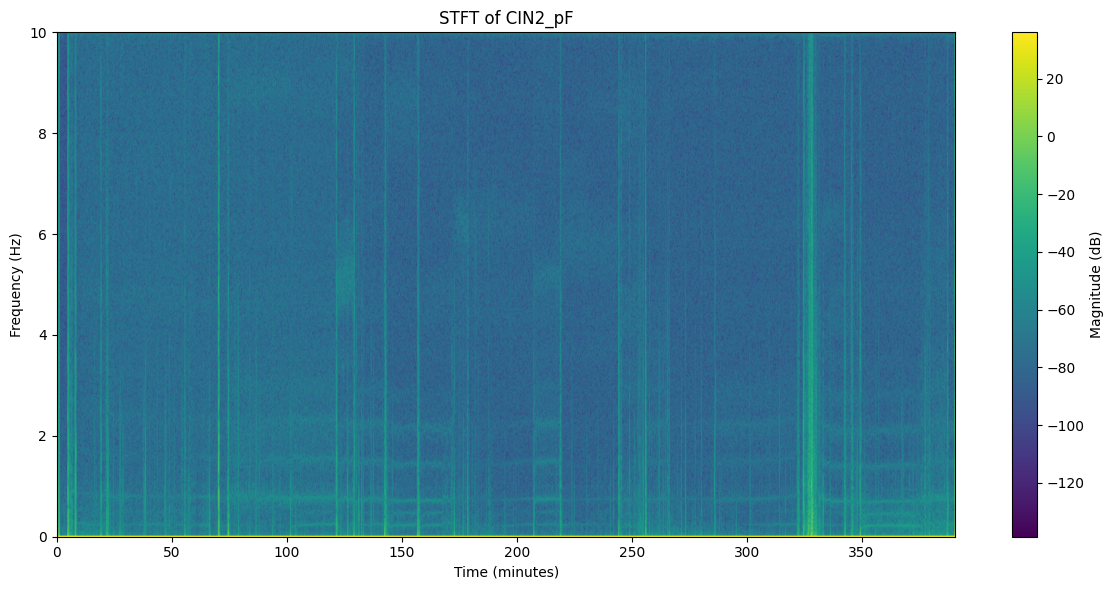

In [30]:
from scipy.signal import stft
import numpy as np

# Prepare the signal and sampling frequency
signal = capacitance_1.to_numpy(dtype=float)
valid = np.isfinite(signal)

signal = signal[valid]
time_seconds = time.to_numpy()[valid] / 1000
sampling_frequency = 1 / np.median(np.diff(time_seconds))

# Compute the STFT
frequencies, stft_times, stft_values = stft(
    signal,
    fs=int(sampling_frequency),
    nperseg=1024,
    noverlap=768
)

# Convert magnitude to decibels
stft_magnitude_db = 20 * np.log10(np.maximum(np.abs(stft_values), 1e-12))

# Plot the STFT
plt.figure(figsize=(12, 6))
plt.pcolormesh(
    stft_times / 60,
    frequencies,
    stft_magnitude_db,
    shading="gouraud",
    cmap="viridis"
)
plt.colorbar(label="Magnitude (dB)")
plt.xlabel("Time (minutes)")
plt.ylabel("Frequency (Hz)")
plt.title(f"STFT of {capacitance_1_key}")
plt.ylim(0, sampling_frequency / 2)
plt.tight_layout()
plt.show()

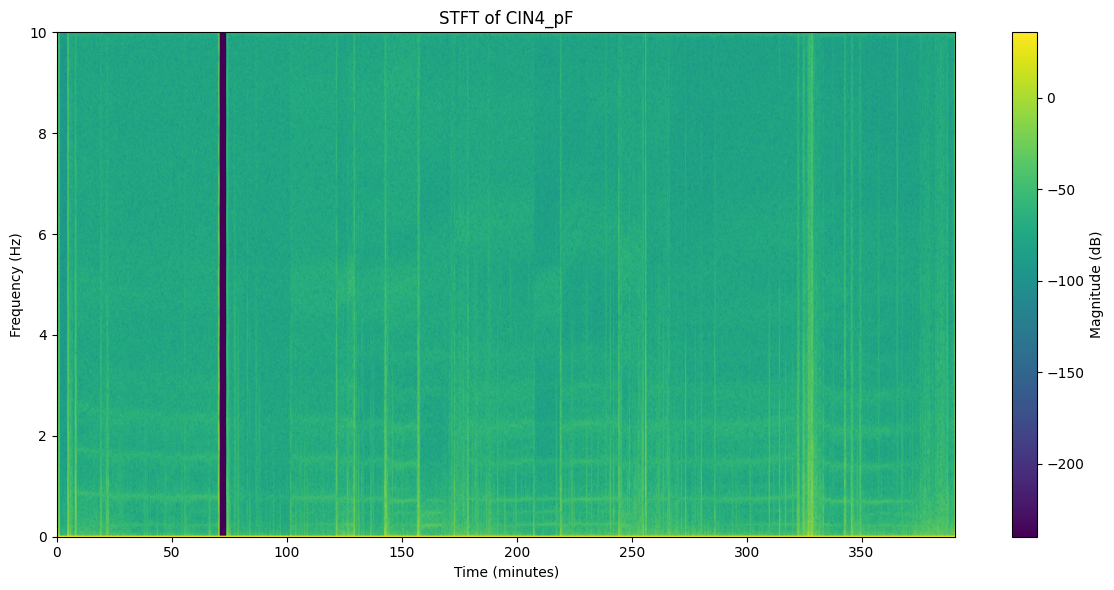

In [31]:
from scipy.signal import stft
import numpy as np

# Prepare the signal and sampling frequency
signal = capacitance_2.to_numpy(dtype=float)
valid = np.isfinite(signal)

signal = signal[valid]
time_seconds = time.to_numpy()[valid] / 1000
sampling_frequency = 1 / np.median(np.diff(time_seconds))

# Compute the STFT
frequencies, stft_times, stft_values = stft(
    signal,
    fs=int(sampling_frequency),
    nperseg=1024,
    noverlap=768
)

# Convert magnitude to decibels
stft_magnitude_db = 20 * np.log10(np.maximum(np.abs(stft_values), 1e-12))

# Plot the STFT
plt.figure(figsize=(12, 6))
plt.pcolormesh(
    stft_times / 60,
    frequencies,
    stft_magnitude_db,
    shading="gouraud",
    cmap="viridis"
)
plt.colorbar(label="Magnitude (dB)")
plt.xlabel("Time (minutes)")
plt.ylabel("Frequency (Hz)")
plt.title(f"STFT of {capacitance_2_key}")
plt.ylim(0, sampling_frequency / 2)
plt.tight_layout()
plt.show()

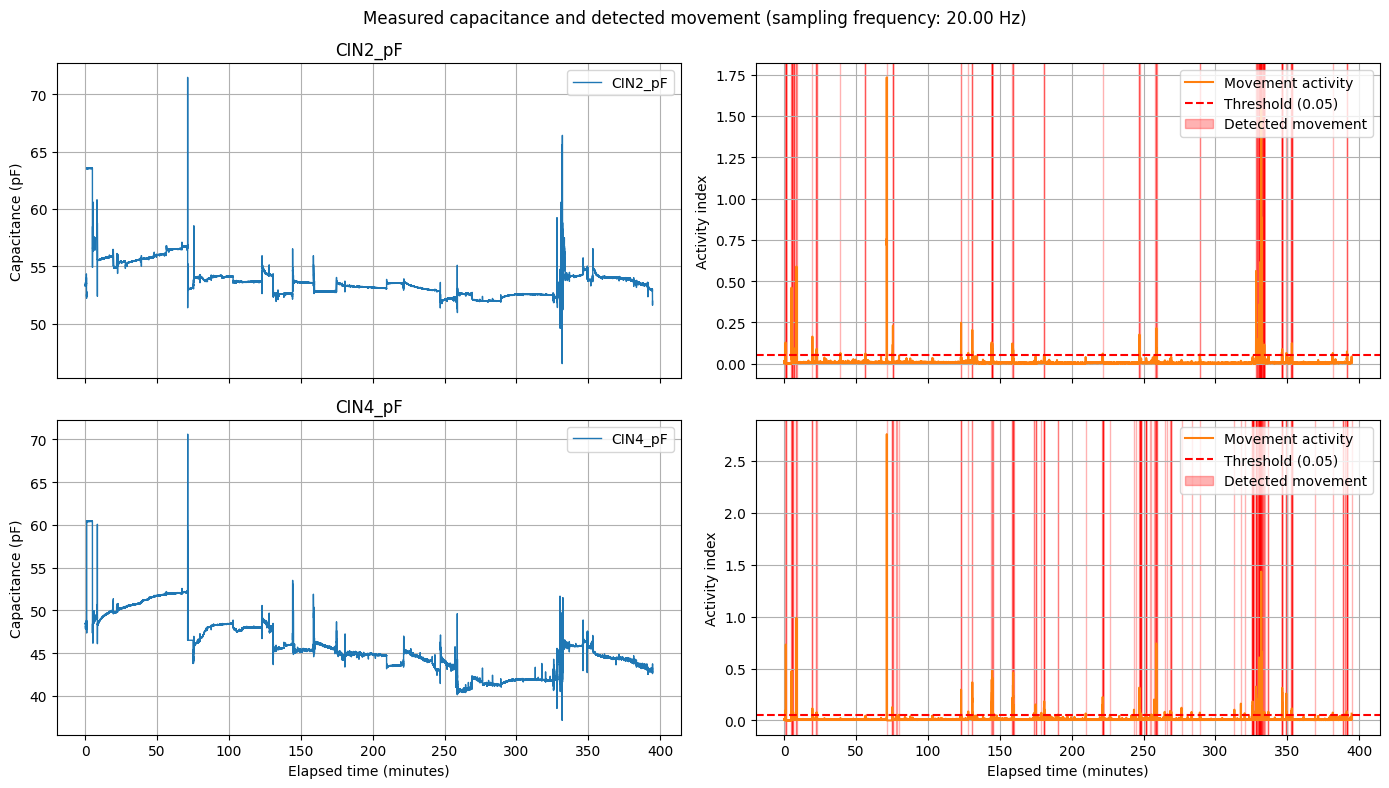

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Detection parameters
window_sec = 1.5
threshold = 0.05

# Use the data, time, and capacitance series loaded in the previous cells.
time_ms = pd.to_numeric(time, errors="coerce")
time_min = (time_ms - time_ms.iloc[0]) / 60000
sampling_frequency = 1000 / np.median(np.diff(time_ms.dropna().to_numpy()))
window_size = max(2, int(round(sampling_frequency * window_sec)))


def detect_movement(capacitance):
    signal = pd.to_numeric(capacitance, errors="coerce")
    diff_series = signal.diff().abs()
    rolling_activity = diff_series.rolling(window=window_size, center=True, min_periods=1).mean()
    movement_detected = rolling_activity > threshold
    return signal, rolling_activity, movement_detected


signals = [
    (capacitance_1_key, *detect_movement(capacitance_1)),
    (capacitance_2_key, *detect_movement(capacitance_2)),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex="col")

for row, (channel_name, signal, rolling_activity, movement_detected) in enumerate(signals):
    axes[row, 0].plot(time_min, signal, label=channel_name, color="tab:blue", linewidth=1)
    axes[row, 0].set_ylabel("Capacitance (pF)")
    axes[row, 0].set_title(channel_name)
    axes[row, 0].grid(True)
    axes[row, 0].legend(loc="upper right")

    axes[row, 1].plot(
        time_min,
        rolling_activity,
        label="Movement activity",
        color="tab:orange",
    )
    axes[row, 1].axhline(
        y=threshold,
        color="r",
        linestyle="--",
        label=f"Threshold ({threshold})",
    )
    axes[row, 1].fill_between(
        time_min,
        0,
        1,
        where=movement_detected,
        color="red",
        alpha=0.3,
        transform=axes[row, 1].get_xaxis_transform(),
        label="Detected movement",
    )
    axes[row, 1].set_ylabel("Activity index")
    axes[row, 1].grid(True)
    axes[row, 1].legend(loc="upper right")

axes[1, 0].set_xlabel("Elapsed time (minutes)")
axes[1, 1].set_xlabel("Elapsed time (minutes)")
fig.suptitle(
    f"Measured capacitance and detected movement "
    f"(sampling frequency: {sampling_frequency:.2f} Hz)"
)
plt.tight_layout()
plt.show()

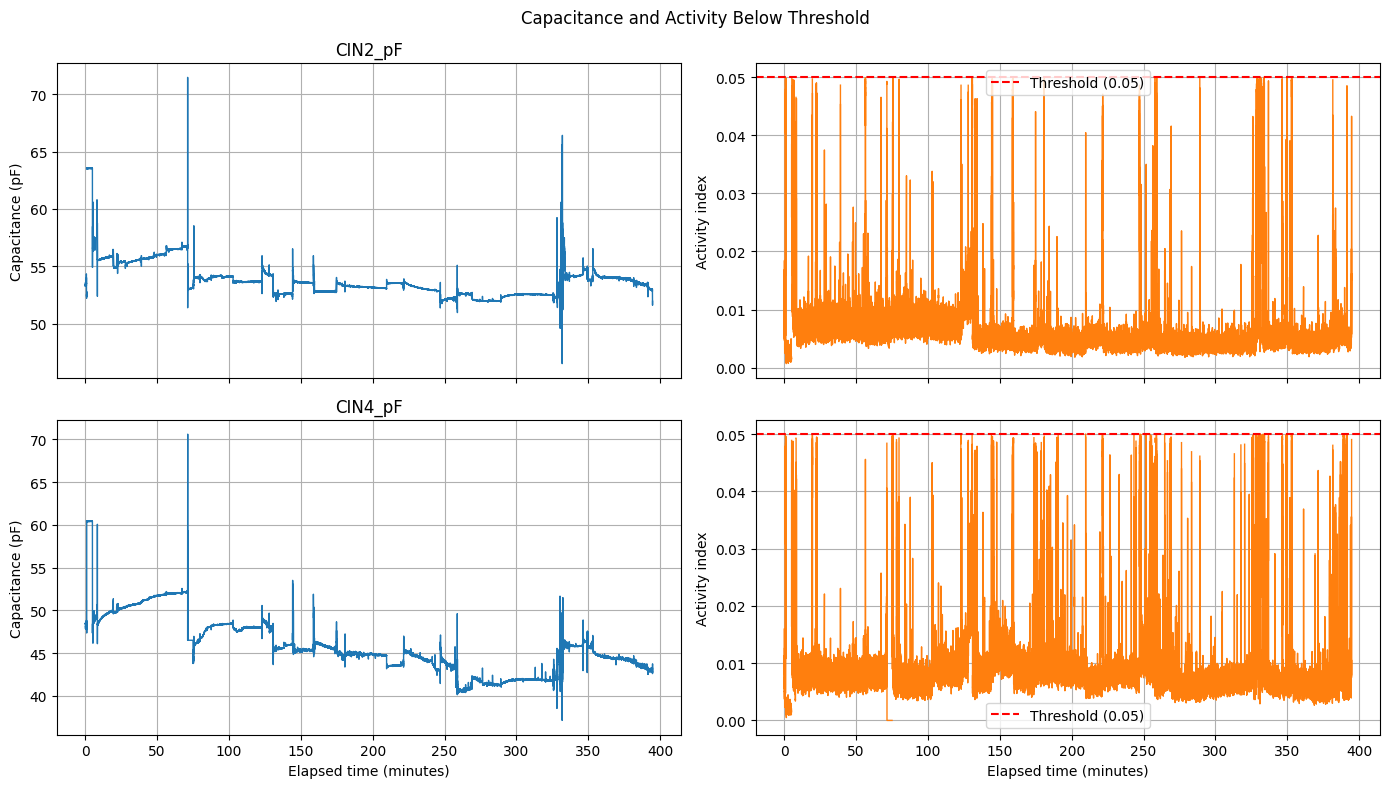

In [33]:
# Plot capacitance and activity while omitting activity values above the threshold
fig_filtered, axes_filtered = plt.subplots(2, 2, figsize=(14, 8), sharex="col")

for row, (channel_name, signal_values, activity_values, _) in enumerate(signals):
    activity_below_threshold = activity_values.where(activity_values <= threshold)

    axes_filtered[row, 0].plot(
        time_min,
        signal_values,
        color="tab:blue",
        linewidth=1,
    )
    axes_filtered[row, 0].set_ylabel("Capacitance (pF)")
    axes_filtered[row, 0].set_title(channel_name)
    axes_filtered[row, 0].grid(True)

    axes_filtered[row, 1].plot(
        time_min,
        activity_below_threshold,
        color="tab:orange",
        linewidth=1,
    )
    axes_filtered[row, 1].axhline(
        threshold,
        color="red",
        linestyle="--",
        label=f"Threshold ({threshold})",
    )
    axes_filtered[row, 1].set_ylabel("Activity index")
    axes_filtered[row, 1].grid(True)
    axes_filtered[row, 1].legend()

axes_filtered[1, 0].set_xlabel("Elapsed time (minutes)")
axes_filtered[1, 1].set_xlabel("Elapsed time (minutes)")

fig_filtered.suptitle("Capacitance and Activity Below Threshold")
plt.tight_layout()
plt.show()

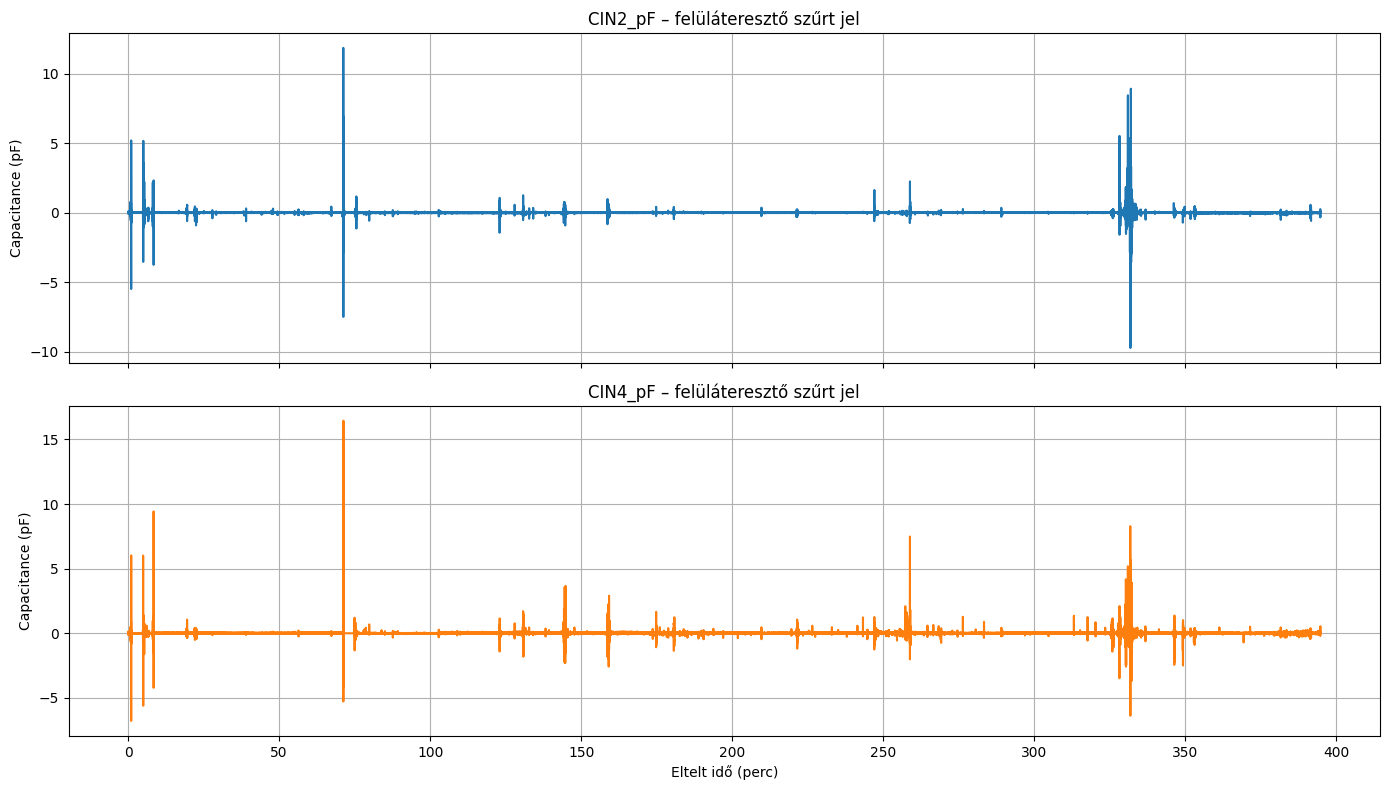

In [34]:
from scipy.signal import butter, sosfiltfilt

# Szűrőparaméterek
cutoff_frequency = 0.2  # Hz
filter_order = 4
nyquist_frequency = sampling_frequency / 2

# Butterworth felüláteresztő szűrő
sos = butter(
    filter_order,
    cutoff_frequency / nyquist_frequency,
    btype="highpass",
    output="sos",
)

capacitance_1_original = (
    pd.to_numeric(capacitance_1, errors="coerce")
    .interpolate(limit_direction="both")
    .to_numpy()
)

capacitance_2_original = (
    pd.to_numeric(capacitance_2, errors="coerce")
    .interpolate(limit_direction="both")
    .to_numpy()
)

capacitance_1_highpass = sosfiltfilt(sos, capacitance_1_original)
capacitance_2_highpass = sosfiltfilt(sos, capacitance_2_original)

# Szűrt jelek ábrázolása
fig_highpass, axes_highpass = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes_highpass[0].plot(time_min, capacitance_1_highpass, color="tab:blue")
axes_highpass[0].set_ylabel("Capacitance (pF)")
axes_highpass[0].set_title(f"{capacitance_1_key} – felüláteresztő szűrt jel")
axes_highpass[0].grid(True)

axes_highpass[1].plot(time_min, capacitance_2_highpass, color="tab:orange")
axes_highpass[1].set_xlabel("Eltelt idő (perc)")
axes_highpass[1].set_ylabel("Capacitance (pF)")
axes_highpass[1].set_title(f"{capacitance_2_key} – felüláteresztő szűrt jel")
axes_highpass[1].grid(True)

plt.tight_layout()
plt.show()

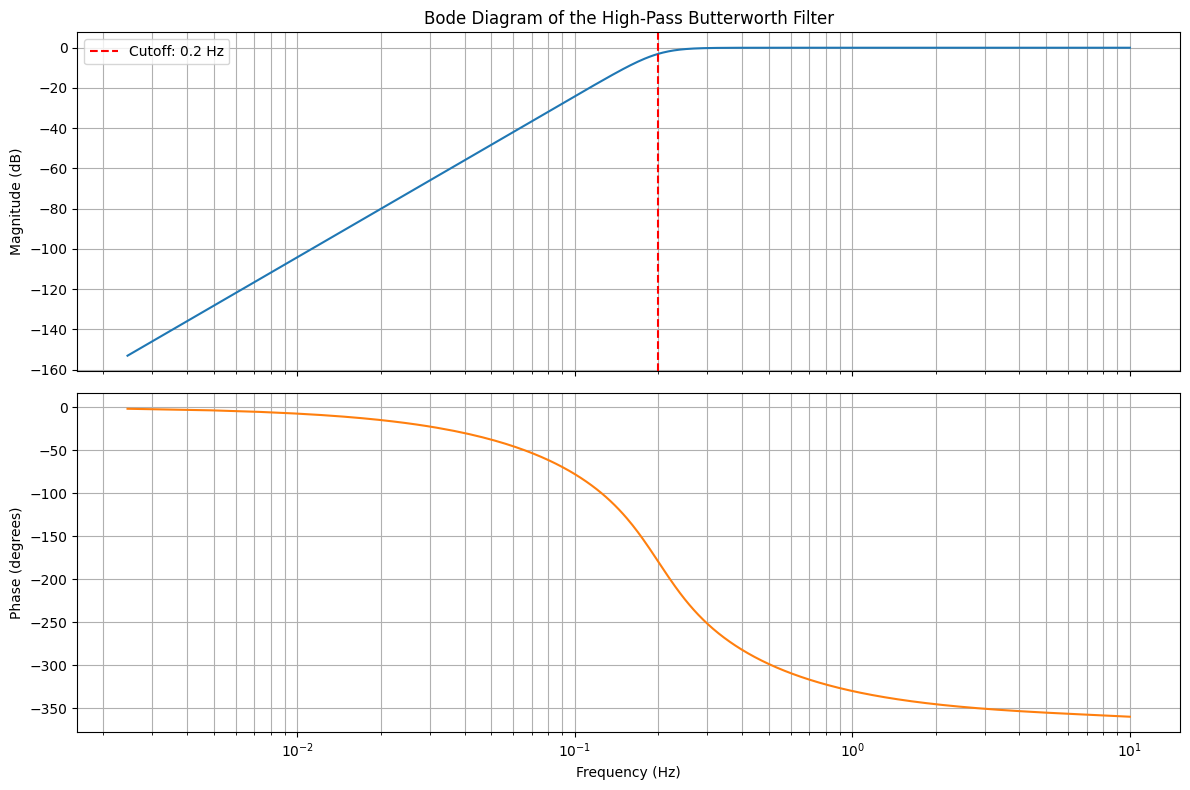

In [35]:
from scipy.signal import sosfreqz

# Frequency response of the Butterworth high-pass filter
frequencies_bode, response = sosfreqz(
    sos,
    worN=4096,
    fs=int(sampling_frequency),
)

magnitude_db = 20 * np.log10(np.maximum(np.abs(response), 1e-12))
phase_degrees = np.unwrap(np.angle(response)) * 180 / np.pi

# Exclude zero frequency for logarithmic plotting
positive = frequencies_bode > 0

fig_bode, axes_bode = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes_bode[0].semilogx(
    frequencies_bode[positive],
    magnitude_db[positive],
    color="tab:blue",
)
axes_bode[0].axvline(
    cutoff_frequency,
    color="red",
    linestyle="--",
    label=f"Cutoff: {cutoff_frequency} Hz",
)
axes_bode[0].set_ylabel("Magnitude (dB)")
axes_bode[0].set_title("Bode Diagram of the High-Pass Butterworth Filter")
axes_bode[0].grid(True, which="both")
axes_bode[0].legend()

axes_bode[1].semilogx(
    frequencies_bode[positive],
    phase_degrees[positive],
    color="tab:orange",
)
axes_bode[1].set_xlabel("Frequency (Hz)")
axes_bode[1].set_ylabel("Phase (degrees)")
axes_bode[1].grid(True, which="both")

plt.tight_layout()
plt.show()